# Demo: klasyfikacja gatunków kwiatów (Oxford Flowers 102)

Notebook ładuje najlepszy wytrenowany model (checkpoint z `checkpoints/`, tworzony przez `src/train.py`) i pokazuje predykcje top-3 na losowych zdjęciach z **testowej** części podziału (seed 6102) oraz na dowolnym własnym zdjęciu.

Wymagania: wcześniej uruchomione `python src/train.py --run <wariant>` (wagi nie są w repozytorium).

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image

import config as C
from data import prepare, class_names, get_transforms
from models import build_model
from utils import get_device

device = get_device()
names = class_names()
df = prepare()
summary = pd.read_csv(C.RESULTS_DIR / "summary.csv")
summary[["wariant", "test accuracy", "test macro-F1", "test top-3", "czas treningu [s]"]]

,wariant,test accuracy,test macro-F1,test top-3,czas treningu [s]
0,ResNet-18 zamrożony (baseline),0.9060,0.8931,0.9695,220
1,ResNet-18 ostatni blok,0.9670,0.9659,0.9976,360
2,ResNet-18 pełny FT,0.9792,0.9799,0.9939,967
3,MobileNetV2 zamrożony,0.9438,0.9336,0.9866,158
4,MobileNetV2 pełny FT,0.9780,0.9761,0.9963,971


In [2]:
# wybór najlepszego wariantu wg accuracy na teście
results = {p.stem: json.loads(p.read_text()) for p in C.RESULTS_DIR.glob("*.json")
           if p.stem in C.VARIANTS}
best = max(results, key=lambda r: results[r]["test_acc"])
cfg = C.VARIANTS[best]
model, *_ = build_model(cfg["arch"], cfg["finetune"], pretrained=False)
model.load_state_dict(torch.load(C.CKPT_DIR / f"{best}.pt", map_location="cpu"))
model.to(device).eval()
print("Model:", best, "| test acc:", round(results[best]["test_acc"], 4), "| device:", device)

Model: r18_full | test acc: 0.9792 | device: mps


In [3]:
tf = get_transforms(train=False)

@torch.no_grad()
def predict(img: Image.Image, k=3):
    img = img.convert("RGB")
    s = C.RESIZE_SHORT / min(img.size)  # ten sam preprocessing co przy treningu
    img = img.resize((round(img.width * s), round(img.height * s)), Image.BICUBIC)
    probs = torch.softmax(model(tf(img).unsqueeze(0).to(device)), 1)[0].cpu()
    p, i = probs.topk(k)
    return [(names[j], float(q)) for j, q in zip(i, p)]

def show(files, labels=None, cols=4):
    rows = int(np.ceil(len(files) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4.2 * cols, 4.6 * rows))
    for ax in np.atleast_1d(axes).flat: ax.axis("off")
    for ax, f, lab in zip(np.atleast_1d(axes).flat, files, labels or [None] * len(files)):
        img = Image.open(f)
        top = predict(img)
        ax.imshow(img)
        ok = lab is None or top[0][0] == names[lab]
        txt = "\n".join(f"{n}: {p:.2f}" for n, p in top)
        if lab is not None: txt = f"GT: {names[lab]}\n" + txt
        ax.set_title(txt, fontsize=9, color="green" if ok else "red")
    plt.tight_layout(); plt.show()

## Losowe zdjęcia testowe (zielone = poprawnie, czerwone = błąd)

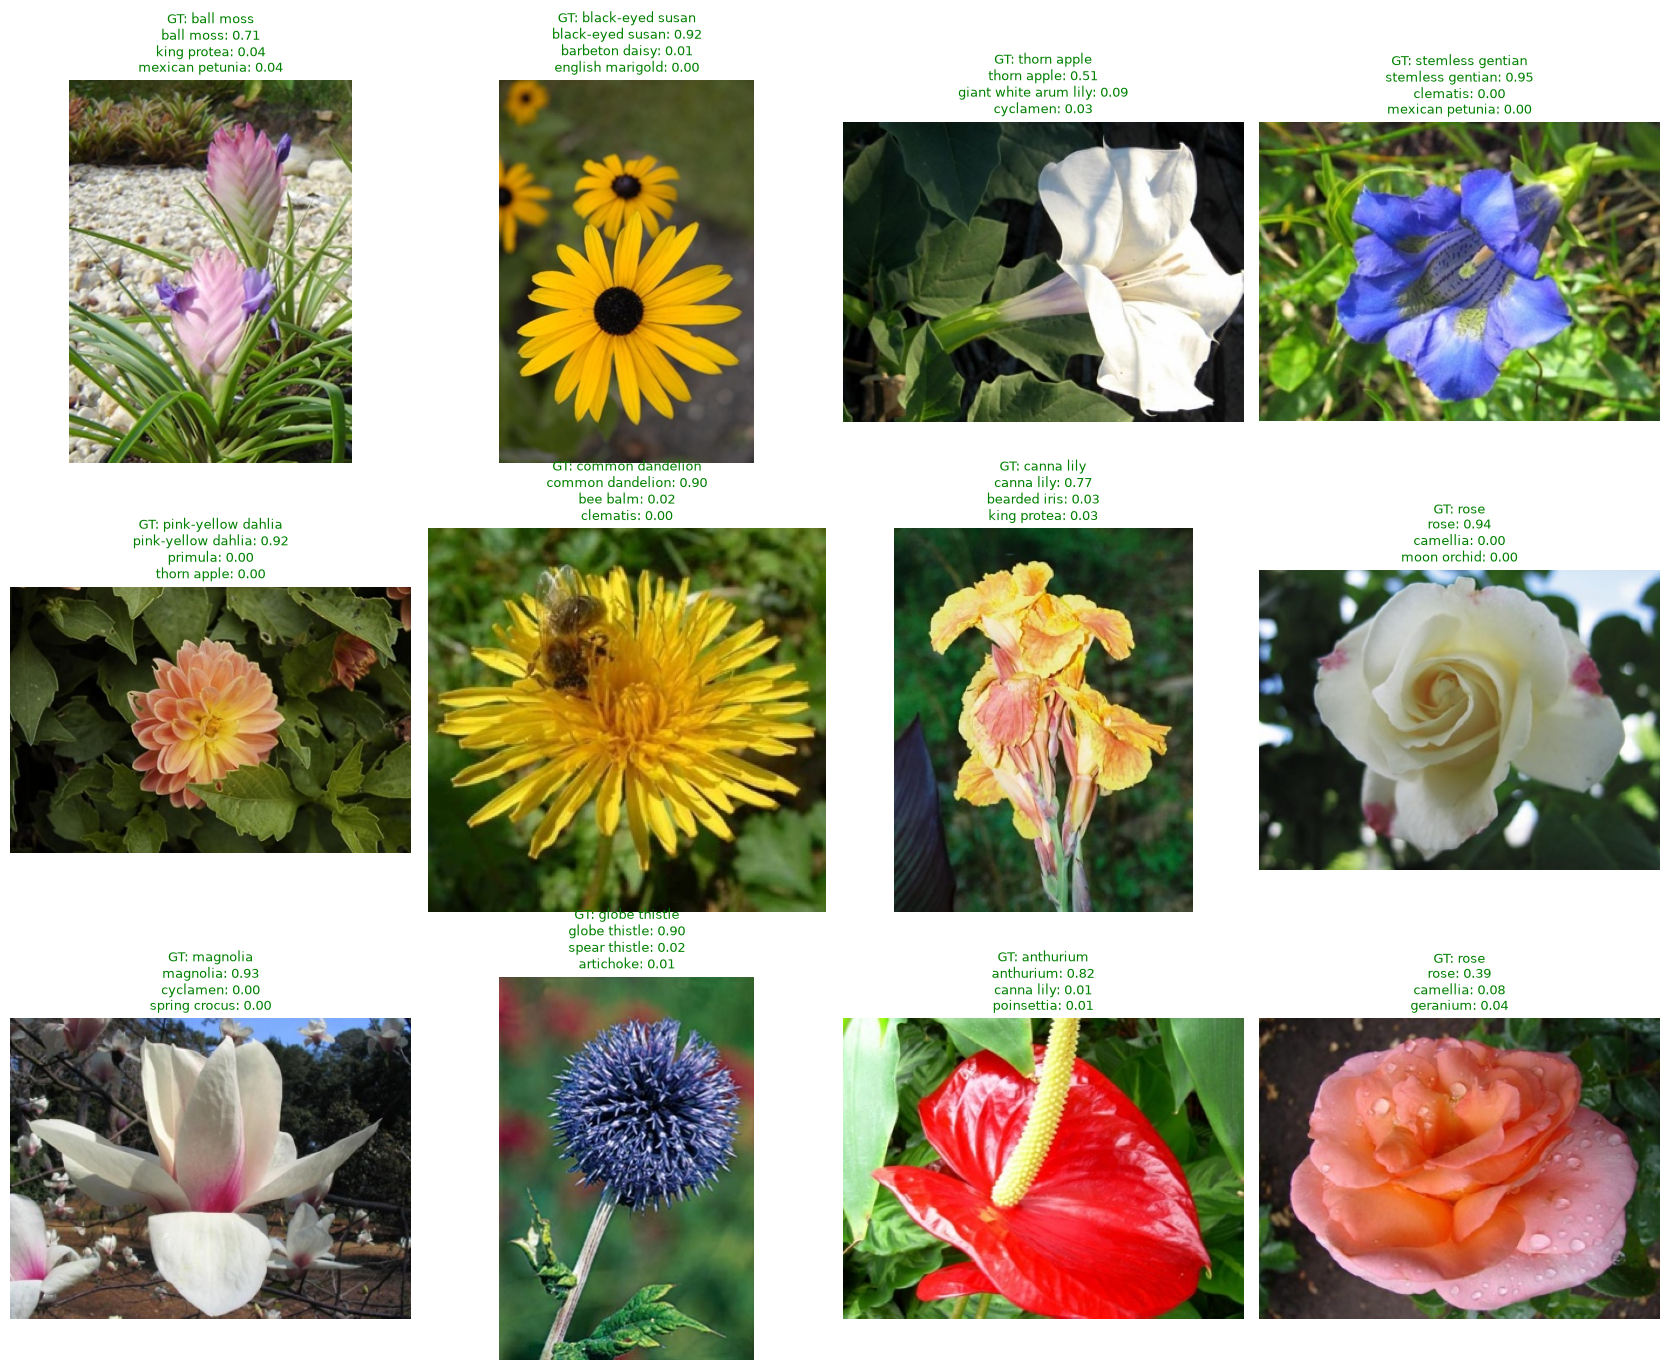

In [4]:
test = df[df.split == "test"].sample(12, random_state=C.SEED)
show([C.CACHE_DIR / f for f in test.file], test.label.tolist())

## Przypadki trudne: zdjęcia testowe, na których model się myli

Błędy: 17 / 819


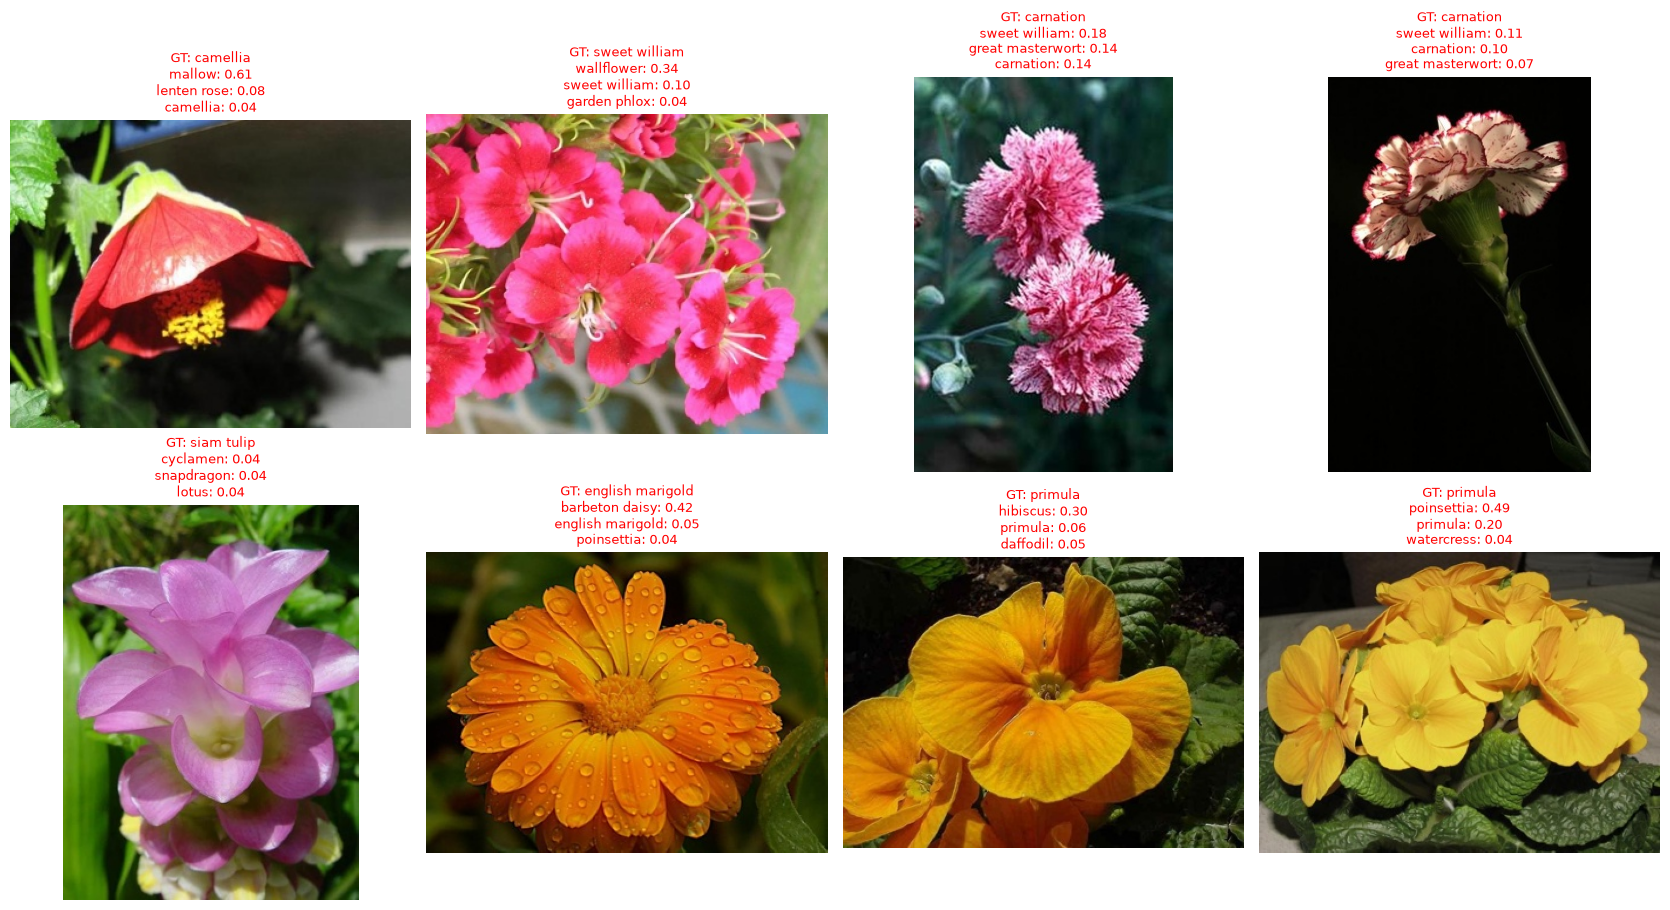

In [5]:
preds = pd.read_csv(C.RESULTS_DIR / f"{best}_test_preds.csv")
wrong = preds[preds.label != preds.pred].head(8)
print(f"Błędy: {(preds.label != preds.pred).sum()} / {len(preds)}")
show([C.CACHE_DIR / f for f in wrong.file], wrong.label.tolist())

## Własne zdjęcie
Podmień ścieżkę na dowolny plik `.jpg` ze zdjęciem kwiatu.

In [6]:
my_image = C.CACHE_DIR / df[df.split == "test"].file.iloc[0]  # <- tu własna ścieżka
predict(Image.open(my_image), k=5)

[('passion flower', 0.8602334856987),
 ('alpine sea holly', 0.0031477841548621655),
 ('artichoke', 0.0030696257017552853),
 ('water lily', 0.002639887621626258),
 ('anthurium', 0.002483953256160021)]